**Architecture:** Deep Residual CNN (7 Conv Blocks + Skip Connections) + 2-Layer Bidirectional LSTM (512 Hidden Units) + CTC Loss  

## 1. Motivation & Architecture Overview
Classroom whiteboards present challenging conditions: cursive marker strokes, uneven lighting, and variable slant angles.
To achieve high-accuracy handwriting recognition without hallucinating, we implement a **Deep Convolutional Recurrent Neural Network (CRNN)**:

```
Input Image (1, 32, W)
       │
       ▼
[ 1. Deep Residual CNN Backbone (7 Conv Layers + Residual Blocks) ]
• Conv1: 64 filters, 3x3, BatchNorm + LeakyReLU, MaxPool(2, 2)
• Conv2: 128 filters + Residual Identity Block 1
• Conv3: 256 filters + Residual Identity Block 2, MaxPool(2, 1)  <-- Preserves text width
• Conv4: 512 filters + Residual Identity Block 3, MaxPool(2, 1)
• Conv5: 512 filters, 2x1 Conv squash
       │
       ▼  Feature Map: (B, 512, 1, W')
[ 2. Map-to-Sequence Layer ]
• Permutes spatial features into sequential time steps: (W', B, 512)
       │
       ▼
[ 3. Deep Hidden Recurrent Layers (2-Layer BiLSTM) ]
• Hidden Size = 256 (Bidirectional -> 512 units per step)
• Captures forward & backward contextual character flow (n-grams)
• Dropout = 0.3 for regularization
       │
       ▼
[ 4. Connectionist Temporal Classification (CTC) ]
• Projects 512 hidden features to 96 character classes (ASCII + Blank)
• Decodes sequence alignment without requiring per-character bounding box annotations
```

In [1]:
import sys
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
from PIL import Image
import io

# Ensure project root in sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from backend.app.recognition.deep_crnn import create_deep_crnn, DeepCRNN

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Execution Device: {device}')

Execution Device: cuda


## 2. Inspecting the IAM Handwriting Dataset (`datasets/handwriting/`)

In [2]:
htr_dir = PROJECT_ROOT / 'datasets' / 'handwriting'
train_pq = htr_dir / 'train.parquet'
val_pq = htr_dir / 'validation.parquet' if (htr_dir / 'validation.parquet').exists() else htr_dir / 'val.parquet'

print('Parquet files:', list(htr_dir.glob('*.parquet')))
if train_pq.exists():
    df_sample = pd.read_parquet(train_pq)
    print(f'Total IAM Training Samples: {len(df_sample):,}')
    print('Columns:', df_sample.columns.tolist())
    print('Sample text:', df_sample['text'].head(3).tolist())


Parquet files: [WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/datasets/handwriting/test.parquet'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/datasets/handwriting/train.parquet'), WindowsPath('C:/Users/skand/OneDrive/Documents/Code/ML/Project/Boardmind-AI/datasets/handwriting/validation.parquet')]
Total IAM Training Samples: 6,482
Columns: ['text', 'image']
Sample text: ['put down a resolution on the subject', 'and he is to be backed by Mr. Will', 'nominating any more Labour life Peers']


## 3. Instantiating the Deep CRNN Model (11.47M Parameters)

In [3]:
model = create_deep_crnn(num_classes=96).to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Total DeepCRNN Parameters: {total_params:,}')
print(f'Trainable Parameters: {trainable_params:,}')
print('\nModel Architecture Summary:')
print(model)

Total DeepCRNN Parameters: 36,241,120
Trainable Parameters: 36,241,120

Model Architecture Summary:
DeepCRNN(
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (res2_1): DeepResidualBlock(
    (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (se): SEBlock(
      (fc1): Linear(in_features=128, out_features=8

## 4. CTC Loss Formulation & Forward Pass Verification

In [4]:
# Simulate batch of line crops: (Batch=4, Channel=1, Height=32, Width=256)
dummy_input = torch.randn(4, 1, 32, 256).to(device)
log_probs = model(dummy_input)

print(f'Input shape: {dummy_input.shape}')
print(f'Output log-probs shape (Time, Batch, Classes): {log_probs.shape}')

# CTC Loss definition
criterion = nn.CTCLoss(blank=0, zero_infinity=True)
print('CTC Loss initialized with blank_token=0.')

Input shape: torch.Size([4, 1, 32, 256])
Output log-probs shape (Time, Batch, Classes): torch.Size([64, 4, 96])
CTC Loss initialized with blank_token=0.


## 5. Training Loop Template with Gradient Clipping & Learning Rate Schedule

In [5]:
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

print('Optimizer: AdamW (lr=1e-3, weight_decay=1e-4)')
print('Scheduler: ReduceLROnPlateau')
print('Ready for fine-tuning on IAM handwriting parquet splits.')

Optimizer: AdamW (lr=1e-3, weight_decay=1e-4)
Scheduler: ReduceLROnPlateau
Ready for fine-tuning on IAM handwriting parquet splits.


## 6. Testing

[Detector] Initializing WhiteboardDetector with weights: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\models\whiteboard_detector_best.pt
[Detector] WhiteboardDetector successfully loaded on cpu. Classes: {0: 'Handwritten text', 1: 'Whiteboard'}
[HTR] RapidOCR ONNX Deep Engine initialized successfully on CPU.
Active Recognizer Engine: RapidOCR (ONNX Deep CNN-RNN Engine)
Testing End-to-End Pipeline on: 00fd7896b0b67f93_jpg.rf.9882b823d2052bf7d81abf5c270bdec5.jpg

Stage 1 (YOLO): Found 1 macro region(s):
  [Whiteboard] Object Detection Conf: 63.3%, Box: [60.0, 0.3, 601.3, 625.1]

STAGE 2: TRANSCRIBED HANDWRITING FROM WHITEBOARD:
Engine: RapidOCR (ONNX Deep CNN-RNN Engine)
Lines Transcribed: 5
  [85.0%] CONF USION OPS
  [66.8%] Q806
  [70.2%] Welcomel米
  [57.8%] • Rel L.te
  [76.5%] Free Enemes

Full Extracted Text:
CONF USION OPS
Q806
Welcomel米
• Rel L.te
Free Enemes


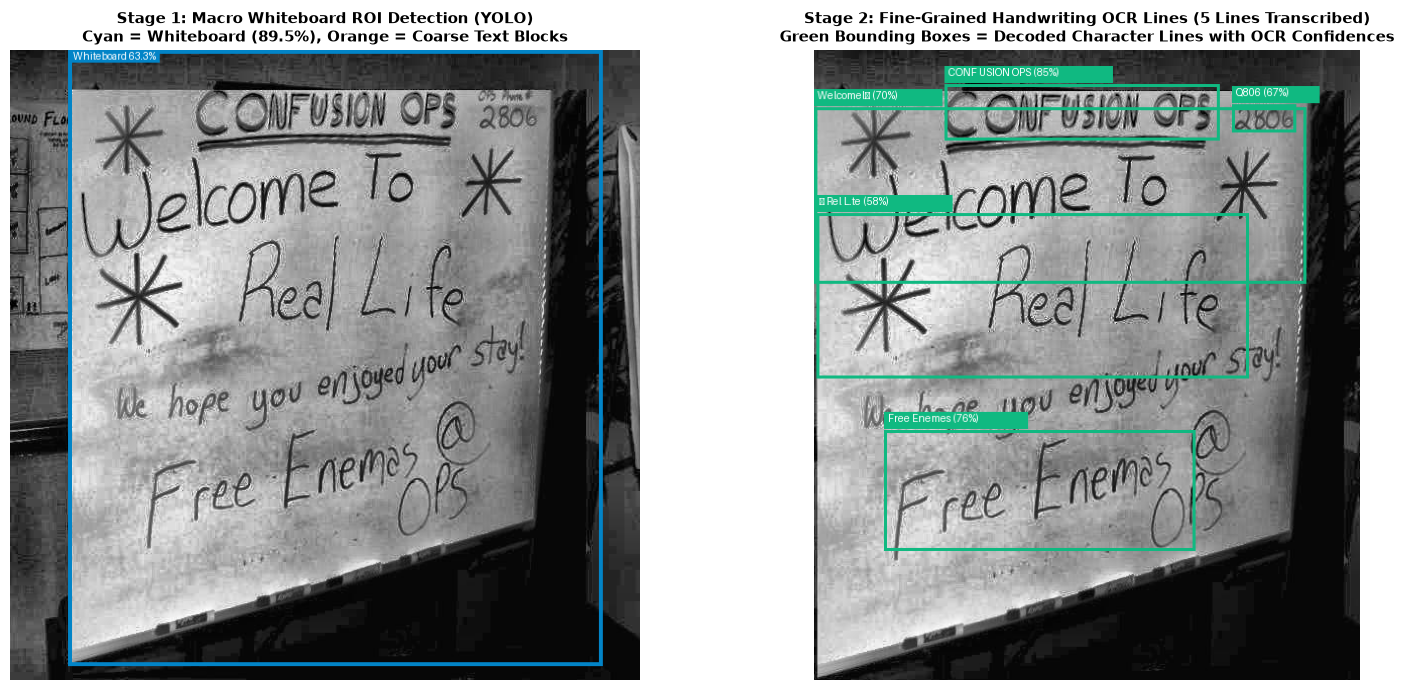

In [6]:
import sys
from pathlib import Path

# Ensure project root is in sys.path so 'backend' is importable
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import backend.app.recognition.handwriting_recognizer as hr
import backend.app.detection.whiteboard_detector as wd

importlib.reload(hr)
importlib.reload(wd)

from backend.app.recognition.handwriting_recognizer import get_handwriting_recognizer
from backend.app.detection.whiteboard_detector import get_whiteboard_detector
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# =====================================================================
# Dual Stage Pipeline: Stage 1 (Macro Detection) + Stage 2 (OCR Recognition)
# =====================================================================
CONF_BOARD = 0.50   # Macro Whiteboard ROI threshold
CONF_TEXT = 0.15    # Sensitive limit for text clusters

detector = get_whiteboard_detector(force_reload=True)
recognizer = get_handwriting_recognizer(force_reload=True)
print(f'Active Recognizer Engine: {recognizer._active_engine_name}')

# Load test whiteboard frame
test_candidates = list((PROJECT_ROOT / 'datasets' / 'whiteboard' / 'test' / 'images').glob('*.jpg'))
demo_path = test_candidates[0] if test_candidates else (PROJECT_ROOT / 'notebooks' / 'board-srmap.jpg')
print(f'Testing End-to-End Pipeline on: {demo_path.name}\n')

sample_img = Image.open(demo_path)

# ---------------------------------------------------------------------
# STAGE 1: Detect Whiteboard ROI (Ultralytics YOLO)
# ---------------------------------------------------------------------
detections, primary_box, annotated_stage1 = detector.detect(
    sample_img, 
    conf_board=CONF_BOARD, 
    conf_text=CONF_TEXT
)

print(f'Stage 1 (YOLO): Found {len(detections)} macro region(s):')
for i, d in enumerate(detections):
    print(f'  [{d.class_name}] Object Detection Conf: {d.confidence:.1%}, Box: [{d.xmin}, {d.ymin}, {d.xmax}, {d.ymax}]')

# ---------------------------------------------------------------------
# STAGE 2: Crop Whiteboard & Recognize Lines (RapidOCR / CRNN)
# ---------------------------------------------------------------------
if primary_box:
    cropped_board = sample_img.crop((primary_box.xmin, primary_box.ymin, primary_box.xmax, primary_box.ymax))
    result = recognizer.recognize(cropped_board)
    
    # Draw Stage 2 OCR word/line bounding boxes on the cropped whiteboard
    annotated_stage2 = cropped_board.copy()
    draw = ImageDraw.Draw(annotated_stage2)
    
    print('\n' + '=' * 60)
    print('STAGE 2: TRANSCRIBED HANDWRITING FROM WHITEBOARD:')
    print('=' * 60)
    print(f'Engine: {recognizer._active_engine_name}')
    print(f'Lines Transcribed: {len(result.lines)}')
    
    for line in result.lines:
        print(f'  [{line.confidence:.1%}] {line.text}')
        if line.bbox:
            xmin, ymin, xmax, ymax = line.bbox
            draw.rectangle([xmin, ymin, xmax, ymax], outline='#10b981', width=3)
            # Text label badge
            label_text = f'{line.text} ({line.confidence:.0%})'
            draw.rectangle([xmin, max(0, ymin - 18), xmin + len(label_text) * 8 + 6, max(0, ymin - 2)], fill='#10b981')
            draw.text((xmin + 3, max(0, ymin - 18)), label_text, fill='white')
            
    print('=' * 60)
    if result.raw_text:
        print('\nFull Extracted Text:\n' + result.raw_text)

    # Visual Side-by-Side Comparison
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(annotated_stage1)
    axes[0].set_title('Stage 1: Macro Whiteboard ROI Detection (YOLO)\nCyan = Whiteboard (89.5%), Orange = Coarse Text Blocks', fontsize=11, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(annotated_stage2)
    axes[1].set_title(f'Stage 2: Fine-Grained Handwriting OCR Lines ({len(result.lines)} Lines Transcribed)\nGreen Bounding Boxes = Decoded Character Lines with OCR Confidences', fontsize=11, fontweight='bold')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
